# Team Karki
## Team member
- Puran Karki
- Santosh Sigdel
- Manoj Bhattarai
- Nabin Yari

# 1. Tree Species Classification

This project develops image classification models for identifying tree species.

The project uses transfer learning with two ResNet architectures:

- ResNet18
- ResNet50

The models will be trained, validated, tested, and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and n-best classification results.

# 2. Import Libraries

In [8]:
import torch.nn as nn
import torch.optim as optim


import matplotlib.pyplot as plt

print("All libraries imported successfully")
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("All libraries imported successfully")

All libraries imported successfully
All libraries imported successfully


# 3. Define Dataset Paths

### Dataset Path

The tree dataset is stored separately from the notebook. Update `data_dir`
below to the local location of the downloaded dataset before running the notebook.

In [9]:
# Update this path to the location of the downloaded tree dataset
data_dir = r"E:\OneDrive\Desktop\Neural_network\tree"

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

print("Train folder:", train_dir)
print("Validation folder:", val_dir)
print("Test folder:", test_dir)

Train folder: E:\OneDrive\Desktop\Neural_network\tree\train
Validation folder: E:\OneDrive\Desktop\Neural_network\tree\val
Test folder: E:\OneDrive\Desktop\Neural_network\tree\test


# 4. Check Dataset Folders

Before loading the images, we check that the training, validation, and test folders exist at the expected locations.

The dataset is divided into three parts:

- **Training set:** used to train the machine learning model.
- **Validation set:** used to monitor the model during development and training.
- **Test set:** used for the final evaluation of the trained model.

This check helps us make sure that the dataset paths are correct before we start loading the images.

In [10]:
print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(val_dir))
print("Test folder exists:", os.path.exists(test_dir))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


# 5. Load the Dataset

The dataset is organized into folders where each folder represents one tree species.

For example, the training folder contains separate folders for different species:

```text
train/
├── Acer palmatum/
├── Cedrus deodara/
├── Celtis sinensis/
├── Ginkgo biloba/
└── ...

In [11]:

train_data = datasets.ImageFolder(train_dir)
val_data = datasets.ImageFolder(val_dir)
test_data = datasets.ImageFolder(test_dir)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# 6. Explore the Tree Species Classes

Each tree species is treated as a separate classification class.

We will now display the class names detected by PyTorch and count how many different species are included in the dataset.

This information is important because the final classification layer of our ResNet models needs one output for each tree species.

In [12]:
print("Tree species/classes:")

for i, class_name in enumerate(train_data.classes):
    print(i, ":", class_name)

print("\nNumber of classes:", len(train_data.classes))

Tree species/classes:
0 : Acer palmatum
1 : Cedrus deodara
2 : Celtis sinensis
3 : Cinnamomum camphora (Linn) Presl
4 : Elaeocarpus decipiens
5 : Flowering cherry
6 : Ginkgo biloba
7 : Koelreuteria paniculata
8 : Lagerstroemia indica
9 : Liquidambar formosana
10 : Liriodendron chinense
11 : Magnolia grandiflora L
12 : Magnolia liliflora Desr
13 : Michelia chapensis
14 : Osmanthus fragrans
15 : Photinia serratifolia
16 : Platanus
17 : Prunus cerasifera f. atropurpurea
18 : Salix babylonica
19 : Sapindus saponaria
20 : Styphnolobium japonicum
21 : Triadica sebifera
22 : Zelkova serrata

Number of classes: 23


# 7. Number of Images

Next, we check the number of images in each part of the dataset.

The training set is used to train the models, the validation set is used during model development, and the test set is kept for the final evaluation.

Knowing the number of images gives us an overview of the size of the dataset before training the models.

In [13]:
print("Number of training images:", len(train_data))
print("Number of validation images:", len(val_data))
print("Number of test images:", len(test_data))

print("\nTotal images:", len(train_data) + len(val_data) + len(test_data))

Number of training images: 3850
Number of validation images: 482
Number of test images: 472

Total images: 4804


# 8. Inspect Example Images

Before applying preprocessing techniques, we inspect several images from the training dataset.

This helps us understand the visual characteristics of the dataset and identify possible issues that could affect classification performance.

We will look for differences such as:

- Image size and aspect ratio
- Lighting conditions
- Backgrounds
- Camera viewpoint
- Tree position in the image
- Image quality
- Visual differences between tree species

These observations will help us decide which preprocessing and data augmentation techniques should be used later.

# 9. Display One Training Image

We first display one image from the training dataset together with its tree species label.

Image size: (1200, 1600)
Label number: 0
Tree species: Acer palmatum


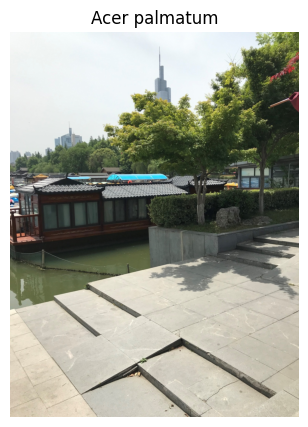

In [14]:
image, label = train_data[0] #gets the first image from the training dataset.

print("Image size:", image.size)
print("Label number:", label)
print("Tree species:", train_data.classes[label])

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

# 10. Inspect the Training Images

## 10.1 Display Several Training Images

Looking at several images gives us a better understanding of the variation within the dataset.

The images may differ in viewpoint, lighting, background, and the position of the tree. These variations are important because the model needs to learn features that are related to the tree species rather than memorizing a particular image background or composition.

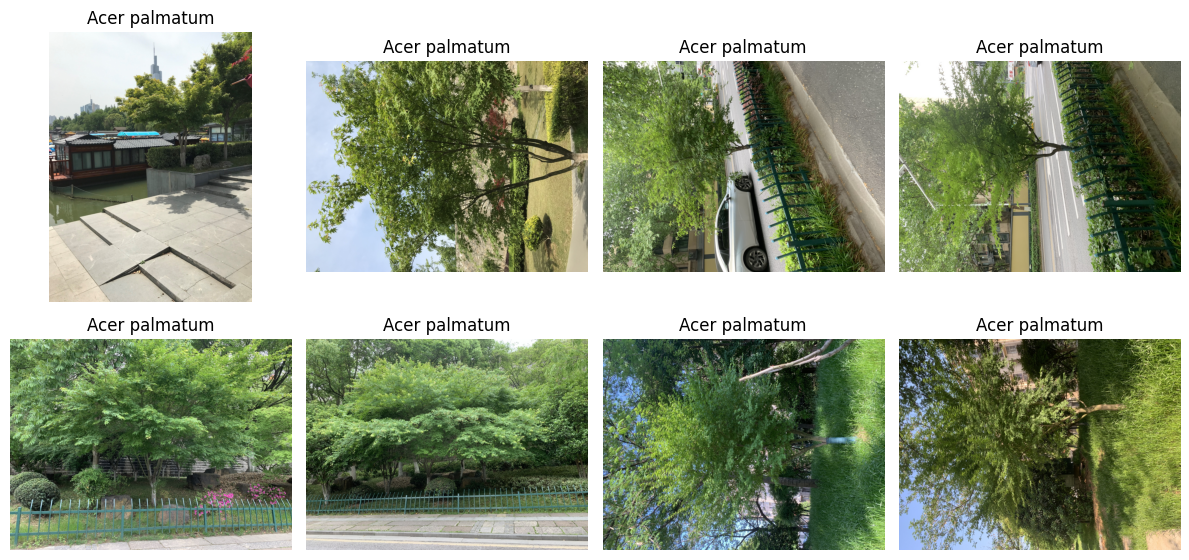

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.2 Check Image Sizes

Images in a dataset may have different resolutions.

We check several images to see whether the dataset contains images with different dimensions.

This is important because the images will later need to be converted into a consistent size before they are given to the neural network.

In [16]:
for i in range(10):
    image, label = train_data[i]
    print(i, train_data.classes[label], image.size)

0 Acer palmatum (1200, 1600)
1 Acer palmatum (1600, 1200)
2 Acer palmatum (1600, 1200)
3 Acer palmatum (1600, 1200)
4 Acer palmatum (1600, 1200)
5 Acer palmatum (1600, 1200)
6 Acer palmatum (1600, 1200)
7 Acer palmatum (1600, 1200)
8 Acer palmatum (1600, 1200)
9 Acer palmatum (1600, 1200)


## 10.3 Inspect Images from Different Tree Species

The previous examples mainly came from the first class because the images in the dataset are organized by class.

To better understand the dataset, we now display one example image from each of several different tree species.

This allows us to compare the visual characteristics of different classes and identify possible differences in image orientation, background, lighting, and image composition.

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

# Select one image from 12 different classes
for i, ax in enumerate(axes.flat):
    class_name = train_data.classes[i]
    
    # Find the first image belonging to this class
    for image_index in range(len(train_data)):
        _, label = train_data[image_index]
        
        if label == i:
            image, _ = train_data[image_index]
            break
    
    ax.imshow(image)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.4 Investigate Image Orientation

The initial inspection showed that the dataset contains both portrait and landscape images.

Some images also appear to have different orientations. We therefore inspect the dimensions of images from different classes before deciding whether additional preprocessing is necessary.

The goal is to determine whether the variation is simply due to different aspect ratios or whether some images require orientation correction.

In [ ]:
for class_index in range(10):
    class_name = train_data.classes[class_index]
    
    for image_index in range(len(train_data)):
        image, label = train_data[image_index]
        
        if label == class_index:
            print(class_name, "->", image.size)
            break

Acer palmatum -> (1200, 1600)
Cedrus deodara -> (1600, 1200)
Celtis sinensis -> (1600, 1200)
Cinnamomum camphora (Linn) Presl -> (1200, 1600)
Elaeocarpus decipiens -> (1600, 1200)
Flowering cherry -> (1600, 1200)
Ginkgo biloba -> (1600, 1200)
Koelreuteria paniculata -> (1600, 1200)
Lagerstroemia indica -> (1600, 1200)
Liquidambar formosana -> (1600, 1200)


## 10.5 Inspect Random Training Images

To avoid examining only the first images of the dataset, we also display randomly selected training images.

This gives us a more representative view of the dataset and helps identify whether image orientation, lighting, background, or quality problems occur throughout the dataset.

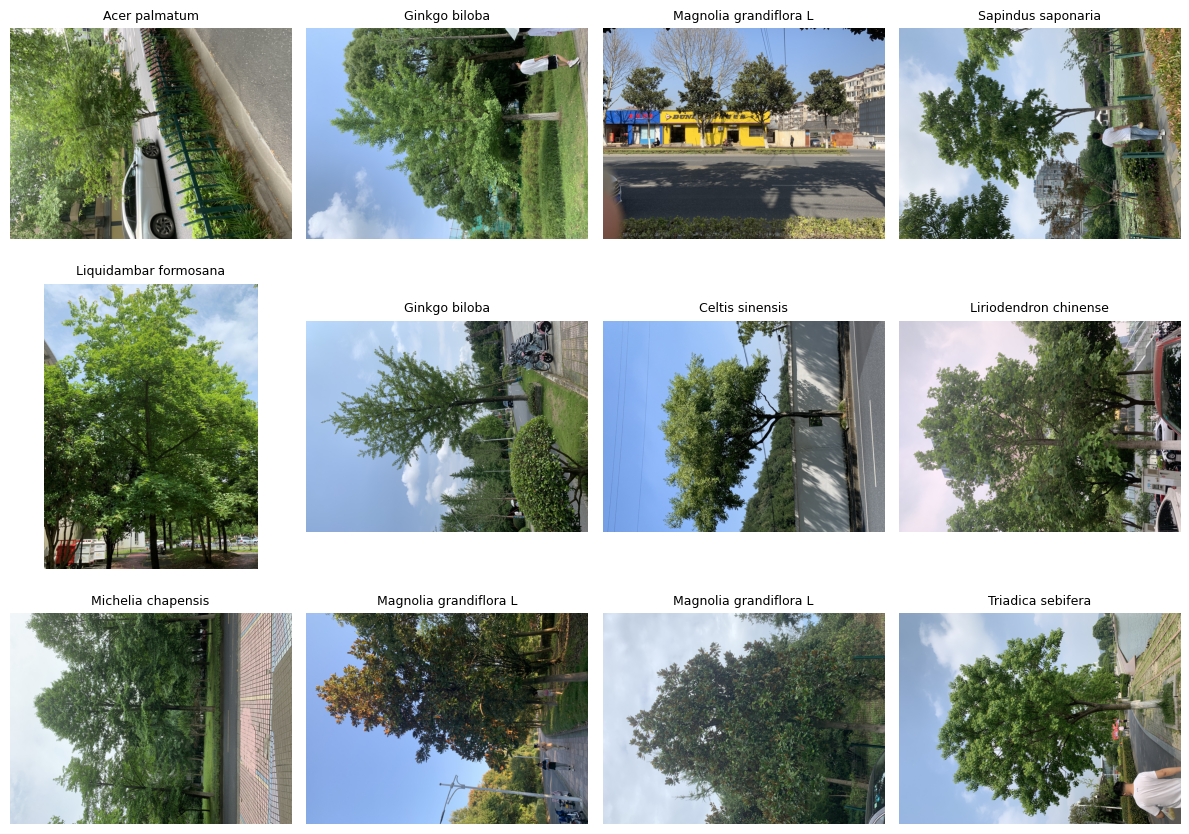

In [ ]:
import random

random_indices = random.sample(range(len(train_data)), 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, index in zip(axes.flat, random_indices):
    image, label = train_data[index]
    
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.6 Check Image Orientation Metadata

During the image inspection, several images appeared to be rotated.

Before applying any rotation manually, we check whether the images contain EXIF orientation information.

EXIF metadata can contain information about how an image should be displayed. If this information is present, it can be corrected when the image is loaded.

This helps us avoid unnecessarily modifying images that are already stored correctly.

In [ ]:
%pip install Pillow

from PIL import Image

image, label = train_data[0]

print("Image:", train_data.classes[label])
print("Image size:", image.size)

exif = image.getexif()

if 274 in exif:
    print("EXIF orientation:", exif[274])
else:
    print("No EXIF orientation information found.")

Note: you may need to restart the kernel to use updated packages.
Image: Acer palmatum
Image size: (1200, 1600)
No EXIF orientation information found.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 10.7 Check Class Distribution

The dataset contains 23 different tree species.

Before training the models, we check how many images are available for each species.

This helps us identify whether the dataset is reasonably balanced or whether some tree species have significantly more images than others.

Class imbalance can affect model performance because a model may have more opportunities to learn classes with a larger number of training images.

In [ ]:
from collections import Counter

class_counts = Counter(train_data.targets)

print("Training images per class:\n")

for class_index, count in class_counts.items():
    print(train_data.classes[class_index], ":", count)

Training images per class:

Acer palmatum : 162
Cedrus deodara : 125
Celtis sinensis : 188
Cinnamomum camphora (Linn) Presl : 234
Elaeocarpus decipiens : 172
Flowering cherry : 106
Ginkgo biloba : 228
Koelreuteria paniculata : 223
Lagerstroemia indica : 65
Liquidambar formosana : 168
Liriodendron chinense : 182
Magnolia grandiflora L : 212
Magnolia liliflora Desr : 190
Michelia chapensis : 154
Osmanthus fragrans : 173
Photinia serratifolia : 120
Platanus : 193
Prunus cerasifera f. atropurpurea : 99
Salix babylonica : 136
Sapindus saponaria : 224
Styphnolobium japonicum : 157
Triadica sebifera : 154
Zelkova serrata : 185


## 10.8 Visualize the Class Distribution

A bar chart makes it easier to see whether some tree species have substantially more training images than others.

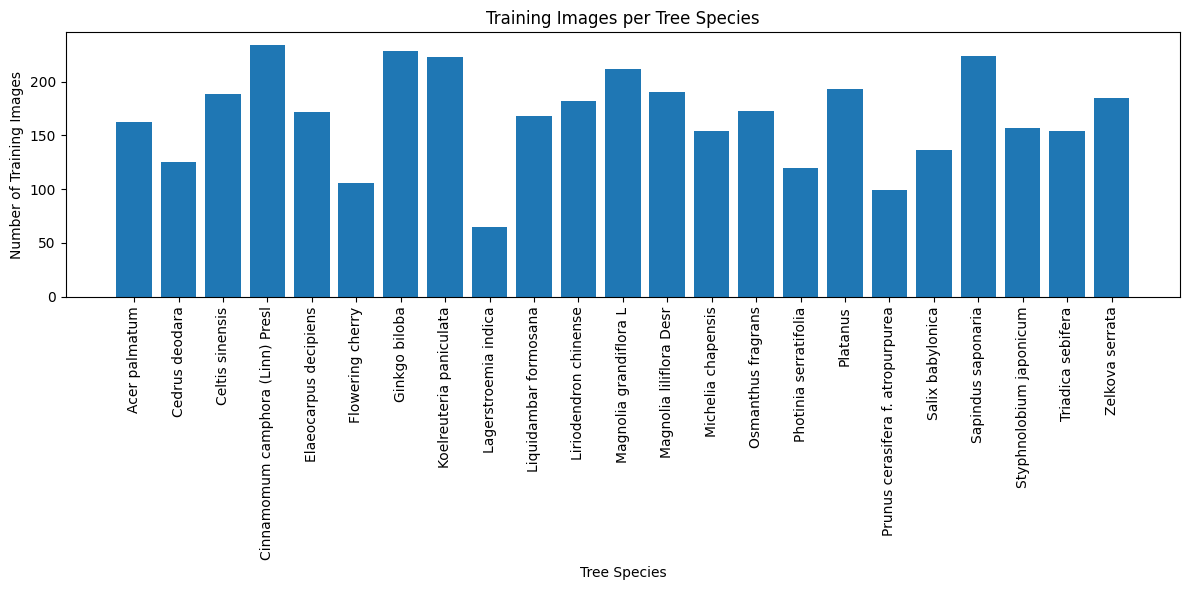

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    train_data.classes,
    [class_counts[i] for i in range(len(train_data.classes))]
)

plt.xlabel("Tree Species")
plt.ylabel("Number of Training Images")
plt.title("Training Images per Tree Species")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# 11. Image Preprocessing

The dataset contains images with different resolutions and orientations. Before training the neural networks, the images need to be converted into a consistent format.

Because we are using pretrained ResNet models, the images will be processed using a format suitable for ImageNet-pretrained networks.

For the training data, we use data augmentation to introduce some variation into the images. This can help the model generalize better to images that it has not seen during training.

The validation and test images are only resized and normalized. Random augmentation is not applied to these datasets because they should provide a consistent evaluation of the models.

The preprocessing steps are:

- Resize and crop images to 224 × 224 pixels.
- Apply small random rotations during training.
- Apply random horizontal flipping during training.
- Convert images to PyTorch tensors.
- Normalize the images using the standard ImageNet mean and standard deviation.

## 11.1 Training Transformations

The training images use data augmentation because the dataset contains trees photographed from different viewpoints and under different conditions.

A small random rotation is used because the dataset contains images with different orientations. A horizontal flip is also used to create additional variation.

We use moderate transformations rather than strong transformations because excessive changes could make the tree species harder to recognize.

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=(128, 128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations created successfully!")

Training transformations created successfully!


## 11.2 Validation and Test Transformations

The validation and test datasets should not use random augmentation.

We want the models to be evaluated using a consistent preprocessing procedure.

Therefore, validation and test images are resized, converted to tensors, and normalized using the same ImageNet normalization values.

In [ ]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation and test transformations created successfully!")

Validation and test transformations created successfully!


## 11.3 Create Transformed Datasets

We now apply the training transformations to the training dataset and the evaluation transformations to the validation and test datasets.

The original datasets used above were useful for inspecting the images. These new datasets will be used for training and evaluation.

In [ ]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Transformed datasets created successfully!")

Transformed datasets created successfully!


## 11.4 Check a Preprocessed Image

We display one transformed image to verify that the preprocessing pipeline works correctly.

Because the image has been normalized, its pixel values are no longer directly suitable for normal display. Therefore, we reverse the normalization before displaying it.

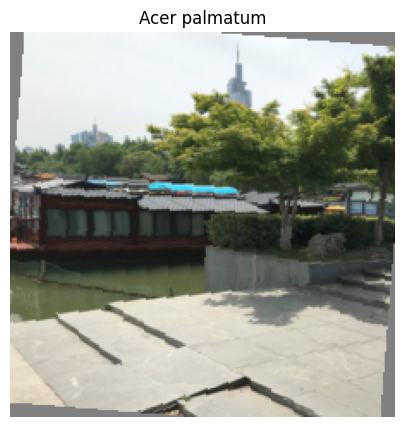

Processed image shape: torch.Size([3, 224, 224])


In [ ]:
image, label = train_dataset[0]

# Reverse ImageNet normalization for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image.numpy().transpose(1, 2, 0)
image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(image_display)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Processed image shape:", image.shape)

# 12. Create DataLoaders

The datasets contain thousands of images, so we do not send all images to the neural network at the same time.

PyTorch DataLoader divides the dataset into smaller batches.

We use a batch size of 32. During training, the training images are shuffled so that the model does not always see the images in the same order.

The validation and test datasets are not shuffled because their purpose is evaluation, where a consistent order is sufficient.

In [ ]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


## 12.1 Check One Training Batch

Before starting model training, we check one batch from the training DataLoader.

The expected image tensor shape is:

`[batch size, channels, height, width]`

For our project this should be approximately:

`[32, 3, 224, 224]`

In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First few labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First few labels: tensor([ 3,  2,  8, 20,  2,  7, 19, 18,  6,  6])


## 12.2 Display a Training Batch

We display several images from one training batch to confirm that the DataLoader is providing correctly transformed images and their corresponding tree species labels.

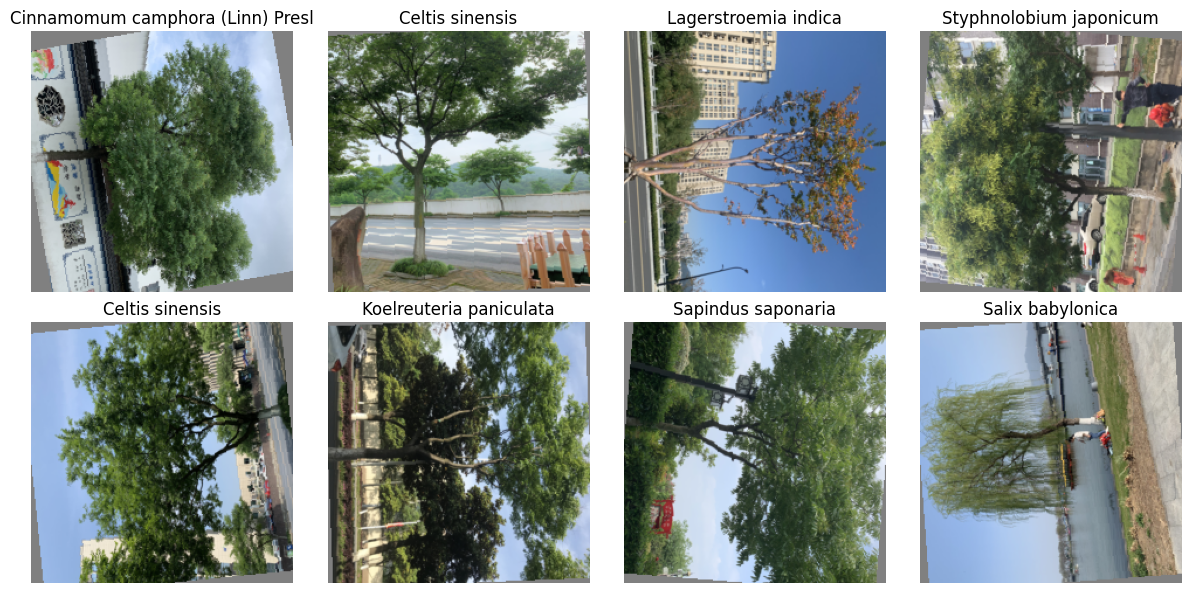

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes.flat):

    image = images[i].numpy().transpose(1, 2, 0)

    # Reverse normalization for display
    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

# 13. Model Development and Training

In this section, we develop the image classification models for the tree species dataset.

The project uses transfer learning with two different ResNet architectures:

- ResNet18
- ResNet50

Both models were originally trained on the ImageNet dataset. Instead of training a convolutional neural network completely from the beginning, we use the pretrained models and adapt their final classification layer to our tree species dataset.

Our dataset contains 23 different tree species, so the final classification layer of each model must produce 23 output classes.

The models will be trained using the training dataset and evaluated using the validation dataset during model development.

The main steps in this section are:

1. Adapt ResNet18 to the tree dataset.
2. Define the loss function and optimizer.
3. Train ResNet18.
4. Validate ResNet18.
5. Adapt ResNet50 to the tree dataset.
6. Train ResNet50.
7. Validate ResNet50.
8. Compare the training and validation results.

## 13.1 Transfer Learning Setup

We use two ImageNet-pretrained models: ResNet18 and ResNet50.
ResNet18 is the smaller architecture, while ResNet50 is deeper.

For each model, we replace the original classification layer
with a new layer containing 23 outputs.

We fine-tune all layers using cross-entropy loss and the Adam
optimizer. Both models use a learning rate of 0.0001, batch
size of 32, and five training epochs.

The validation dataset is used to select the best checkpoint.
The selected checkpoint is then loaded for test evaluation.

In [ ]:
num_classes = len(train_dataset.classes)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Number of classes:", num_classes)
print("PyTorch version:", torch.__version__)
print("Using device:", device)

Number of classes: 23
PyTorch version: 2.12.0+cpu
Using device: cpu


## 13.3 Define the Best-Model Training Function

During training, the validation accuracy may increase and decrease between epochs.

Therefore, we do not simply use the model from the final epoch.

Instead, we keep track of the best validation accuracy and save the model whenever a new best validation result is obtained.

This allows us to use the model that performed best on the validation dataset for the final test evaluation.

In [ ]:
def train_model_best(model, train_loader, val_loader, criterion, optimizer, epochs, save_path):
    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    best_val_accuracy = 0.0

    for epoch in range(epochs):

        # -------------------------
        # Training
        # -------------------------

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_accuracy = 100 * correct / total

        # -------------------------
        # Validation
        # -------------------------

        model.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = running_loss / len(val_loader)
        val_accuracy = 100 * correct / total

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        # -------------------------
        # Save best model
        # -------------------------

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                save_path
            )

            print(f"Best model saved to {save_path}")

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Train Accuracy: {train_accuracy:.2f}% "
            f"Val Loss: {val_loss:.4f} "
            f"Val Accuracy: {val_accuracy:.2f}%"
        )

    print("Best validation accuracy:", best_val_accuracy)

    return (
        train_losses,
        val_losses,
        train_accuracies,
        val_accuracies
    )

## 13.8 Prepare the Final ResNet18 Model

A fresh pretrained ResNet18 model is created for the final experiment.

The final classification layer is adapted to the 23 tree species in the dataset.

The model will be trained using the training dataset, while the validation
dataset will be used to select the best model based on validation accuracy.

The test dataset is not used during training and is reserved for the final
evaluation.

In [ ]:
# Create a fresh ResNet18 model

model18 = models.resnet18(weights="IMAGENET1K_V1")

# Replace the final classification layer

model18.fc = nn.Linear(
    model18.fc.in_features,
    num_classes
)

# Move model to the selected device

model18 = model18.to(device)

print("Fresh ResNet18 created successfully")
print("Number of classes:", num_classes)

Fresh ResNet18 created successfully
Number of classes: 23


In [ ]:
# Loss function

criterion = nn.CrossEntropyLoss()

# Optimizer

optimizer = optim.Adam(
    model18.parameters(),
    lr=0.0001
)

print("Loss function and optimizer created successfully")

Loss function and optimizer created successfully


## 13.9 Final ResNet18 Model

The ResNet18 model is now ready for the final training experiment.

The model is trained for 5 epochs using the training dataset. During training, the validation dataset is used to monitor model performance.

The best version of the model is selected based on validation accuracy and saved separately.

The test dataset is not used during this training process. It is reserved for the final evaluation of the trained model.

In [ ]:
# Number of epochs for the final training

epochs = 5

# Train ResNet18 and keep the best validation model

train_losses18, val_losses18, train_accuracies18, val_accuracies18 = train_model_best(
    model18,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    "resnet18_best.pth"
)

Best model saved to resnet18_best.pth
Epoch [1/5] Train Loss: 1.7222 Train Accuracy: 54.16% Val Loss: 0.8285 Val Accuracy: 75.93%
Best model saved to resnet18_best.pth
Epoch [2/5] Train Loss: 0.6413 Train Accuracy: 83.58% Val Loss: 0.5296 Val Accuracy: 84.85%
Best model saved to resnet18_best.pth
Epoch [3/5] Train Loss: 0.3444 Train Accuracy: 91.90% Val Loss: 0.3763 Val Accuracy: 89.83%
Epoch [4/5] Train Loss: 0.2206 Train Accuracy: 94.99% Val Loss: 0.3640 Val Accuracy: 89.83%
Epoch [5/5] Train Loss: 0.1602 Train Accuracy: 96.29% Val Loss: 0.3440 Val Accuracy: 88.80%
Best validation accuracy: 89.83402489626556


In [ ]:
import os

model_path = "resnet18_best.pth"

if os.path.exists(model_path):
    print("Best ResNet18 model file found!")
    print("File:", model_path)
else:
    print("Best model file was not found.")

Best ResNet18 model file found!
File: resnet18_best.pth


In [ ]:
model18.load_state_dict(torch.load("resnet18_best.pth", map_location=device))

model18 = model18.to(device)

print("Best ResNet18 model loaded successfully!")

Best ResNet18 model loaded successfully!


# 14. ResNet50 Model Development and Training

## 14.1 Load the Pretrained ResNet50 Model

ResNet50 is the second transfer learning architecture used in this project.

Like ResNet18, ResNet50 is a convolutional neural network that was pretrained on the ImageNet dataset.

Instead of training the complete network from the beginning, we use the pretrained model and replace its final classification layer so that it can classify the 23 tree species in our dataset.

In [ ]:
# Load pretrained ResNet50

model50 = models.resnet50(weights="IMAGENET1K_V2")

print("ResNet50 loaded successfully")

ResNet50 loaded successfully


## 14.2 Inspect the Original ResNet50 Classification Layer

The pretrained ResNet50 model was originally trained on ImageNet, which contains 1000 classes.

Our tree dataset contains only 23 classes.

Before replacing the final layer, we inspect the original classification layer to understand its structure.

In [ ]:
print("Original ResNet50 final layer:")
print(model50.fc)

Original ResNet50 final layer:
Linear(in_features=2048, out_features=1000, bias=True)


## 14.3 Adapt ResNet50 for the Tree Dataset

The original ResNet50 classification layer produces 1000 outputs because it was trained on ImageNet.

Our dataset contains 23 tree species.

Therefore, we replace the original classification layer with a new fully connected layer containing 23 outputs.

Each output corresponds to one tree species in our dataset.

In [ ]:
# Number of tree species
num_classes = len(train_dataset.classes)

print("Number of classes:", num_classes)

# Replace the final classification layer
model50.fc = nn.Linear(
    model50.fc.in_features,
    num_classes
)
# Move model to selected device
model50 = model50.to(device)

print("New ResNet50 final layer:")
print(model50.fc)

Number of classes: 23
New ResNet50 final layer:
Linear(in_features=2048, out_features=23, bias=True)


## 14.4 Set Loss Function and Optimizer

We use cross-entropy loss for the 23-class tree species classification problem.

The Adam optimizer is used to update the ResNet50 model parameters during training.

In [ ]:
# Loss function
criterion50 = nn.CrossEntropyLoss()

# Optimizer for ResNet50
optimizer50 = optim.Adam(
    model50.parameters(),
    lr=0.0001
)

print("Loss function and optimizer created successfully.")

Loss function and optimizer created successfully.


## 14.5 Final ResNet50 Training

The ResNet50 model is trained for five epochs using the training dataset.

The validation dataset is used to monitor model performance during training.

The model with the highest validation accuracy is saved as `resnet50_best.pth`.

In [ ]:
# Number of epochs for final ResNet50 training
epochs50 = 5

# Train ResNet50 and save the best validation model
train_losses50, val_losses50, train_accuracies50, val_accuracies50 = train_model_best(
    model50,
    train_loader,
    val_loader,
    criterion50,
    optimizer50,
    epochs50,
    "resnet50_best.pth"
)

Best model saved to resnet50_best.pth
Epoch [1/5] Train Loss: 2.4024 Train Accuracy: 36.29% Val Loss: 1.0310 Val Accuracy: 67.63%
Best model saved to resnet50_best.pth
Epoch [2/5] Train Loss: 0.7491 Train Accuracy: 80.36% Val Loss: 0.4838 Val Accuracy: 85.06%
Best model saved to resnet50_best.pth
Epoch [3/5] Train Loss: 0.3225 Train Accuracy: 91.19% Val Loss: 0.3316 Val Accuracy: 91.08%
Best model saved to resnet50_best.pth
Epoch [4/5] Train Loss: 0.1824 Train Accuracy: 94.99% Val Loss: 0.2315 Val Accuracy: 91.91%
Epoch [5/5] Train Loss: 0.1362 Train Accuracy: 96.29% Val Loss: 0.2645 Val Accuracy: 91.49%
Best validation accuracy: 91.90871369294605


## 14.6 Visualize ResNet50 Training Results

The training and validation loss and accuracy are plotted to evaluate how the ResNet50 model learned during training.

These plots help us compare the training and validation performance across epochs and identify possible overfitting or underfitting.

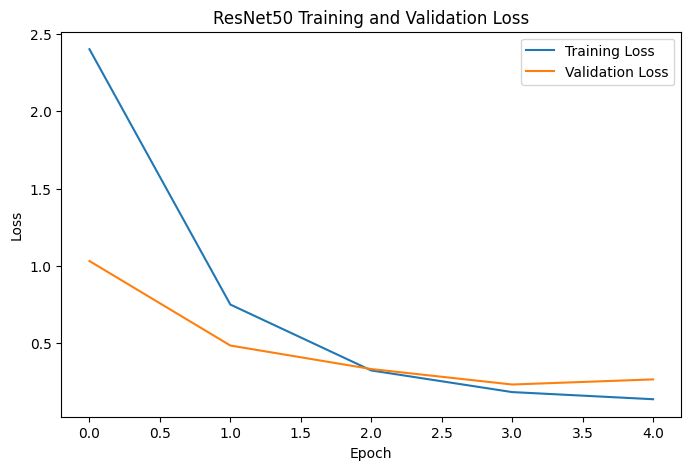

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses50, label="Training Loss")
plt.plot(val_losses50, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.legend()
plt.show()

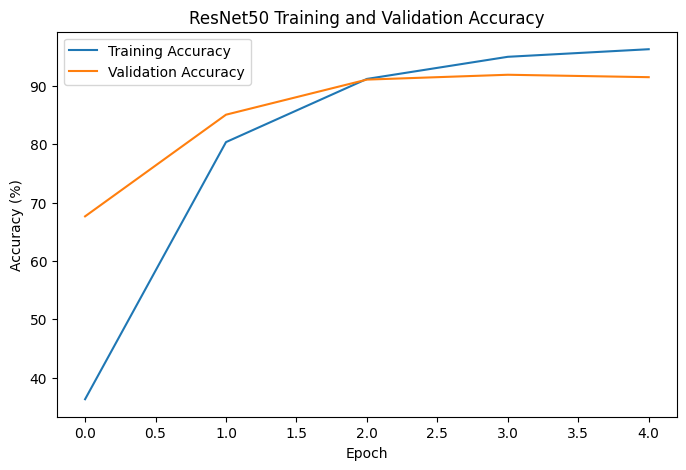

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies50, label="Training Accuracy")
plt.plot(val_accuracies50, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 Training and Validation Accuracy")
plt.legend()
plt.show()

# 15. Model Testing and Evaluation

The trained ResNet18 and ResNet50 models are now evaluated using the test dataset.

The test dataset was not used during model training or validation. It is used only for the final evaluation of the models.

The evaluation will include:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- n-best classification results

The same test dataset is used for both models so that their performance can be compared fairly.

## 15.1 Prepare the Trained Models for Testing

The best model saved during training is loaded before performing the final evaluation.

In [ ]:
import torch

# Load the best ResNet18 model
model18.load_state_dict(torch.load("resnet18_best.pth", map_location=device))
model18 = model18.to(device)
model18.eval()

# Load the best ResNet50 model
model50.load_state_dict(torch.load("resnet50_best.pth", map_location=device))
model50 = model50.to(device)
model50.eval()

print("Best ResNet18 and ResNet50 models loaded successfully.")

Best ResNet18 and ResNet50 models loaded successfully.


## 15.2 Evaluate Model Predictions on the Test Dataset

A common evaluation function is used for both ResNet18 and ResNet50.

The function collects the predicted class and the true class for every image in the test dataset. These predictions will later be used to calculate the evaluation metrics and confusion matrices.

In [ ]:
def get_predictions(model, data_loader):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

In [ ]:
# Get ResNet18 predictions
y_true18, y_pred18, y_prob18 = get_predictions(
    model18,
    test_loader
)

# Get ResNet50 predictions
y_true50, y_pred50, y_prob50 = get_predictions(
    model50,
    test_loader
)

print("ResNet18 predictions collected:", len(y_pred18))
print("ResNet50 predictions collected:", len(y_pred50))

ResNet18 predictions collected: 472
ResNet50 predictions collected: 472


## 15.3 Calculate Accuracy, Precision, Recall and F1-score
The predictions from the test dataset are used to calculate the main classification metrics for both ResNet18 and ResNet50.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score

Macro averaging is used for precision, recall, and F1-score so that each tree species contributes equally to the overall result.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ResNet18 metrics
accuracy18 = accuracy_score(y_true18, y_pred18)
precision18 = precision_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)
recall18 = recall_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)
f1_18 = f1_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)

# ResNet50 metrics
accuracy50 = accuracy_score(y_true50, y_pred50)
precision50 = precision_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)
recall50 = recall_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)
f1_50 = f1_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)

print("ResNet18 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy18:.4f}")
print(f"Precision: {precision18:.4f}")
print(f"Recall   : {recall18:.4f}")
print(f"F1-score : {f1_18:.4f}")

print("\nResNet50 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy50:.4f}")
print(f"Precision: {precision50:.4f}")
print(f"Recall   : {recall50:.4f}")
print(f"F1-score : {f1_50:.4f}")

ResNet18 Test Results
---------------------
Accuracy : 0.8136
Precision: 0.8711
Recall   : 0.8222
F1-score : 0.8254

ResNet50 Test Results
---------------------
Accuracy : 0.8771
Precision: 0.8976
Recall   : 0.8807
F1-score : 0.8831


## 15.4 Confusion Matrix for ResNet18

The confusion matrix shows how the ResNet18 model classified each tree species.

Each row represents the true tree species, while each column represents the predicted species.

The diagonal values represent correctly classified images. 
Values outside the diagonal show which tree species were confused with each other.

This helps us identify specific classes where the model has difficulty distinguishing between similar tree species.

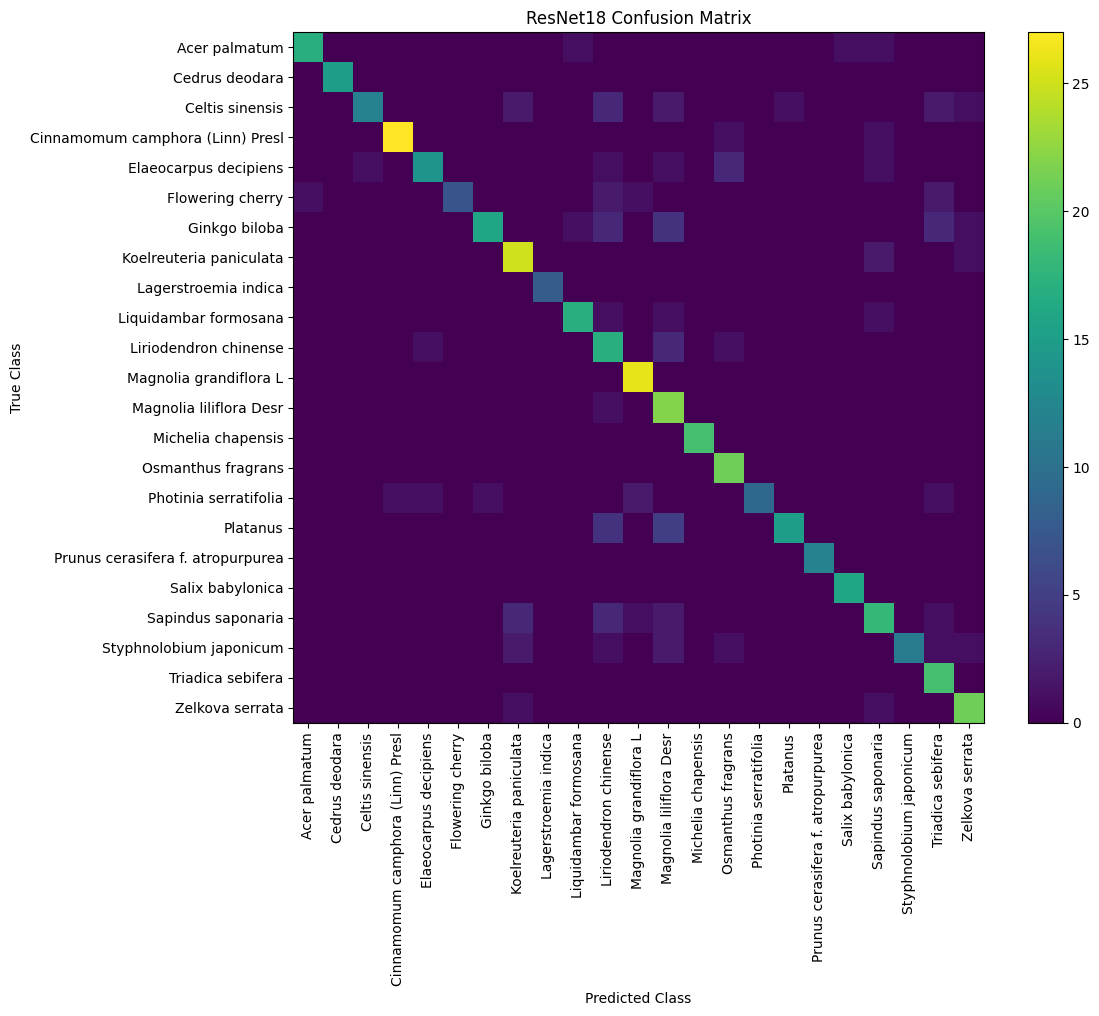

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Calculate confusion matrix for ResNet18
cm18 = confusion_matrix(y_true18, y_pred18)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm18, interpolation="nearest")
plt.title("ResNet18 Confusion Matrix")
plt.colorbar()

# Class names
class_names = test_dataset.classes

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

## 15.5 Confusion Matrix for ResNet50

The same confusion matrix analysis is performed for ResNet50.

The confusion matrix allows us to see which tree species are correctly identified and which species are frequently confused with one another.

This result will later be compared with the ResNet18 confusion matrix.

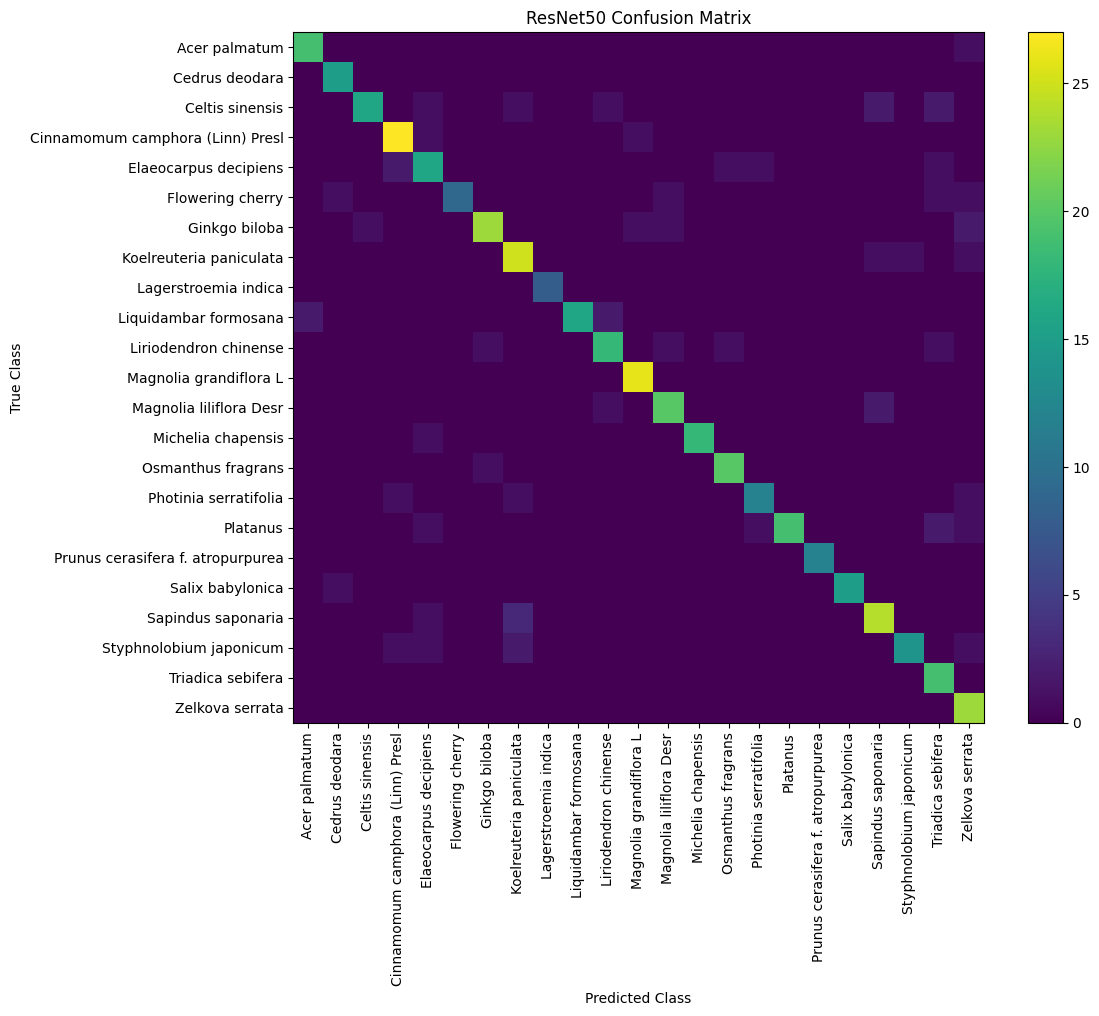

In [ ]:
# Calculate confusion matrix for ResNet50
cm50 = confusion_matrix(y_true50, y_pred50)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm50, interpolation="nearest")
plt.title("ResNet50 Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

## 15.6 Comparison of Confusion Matrices

The two confusion matrices are compared to identify differences in classification behaviour between ResNet18 and ResNet50.

In particular, we look for tree species that are frequently confused by one model but correctly classified by the other.

These differences can provide information about which species are difficult to distinguish based on their visual characteristics.

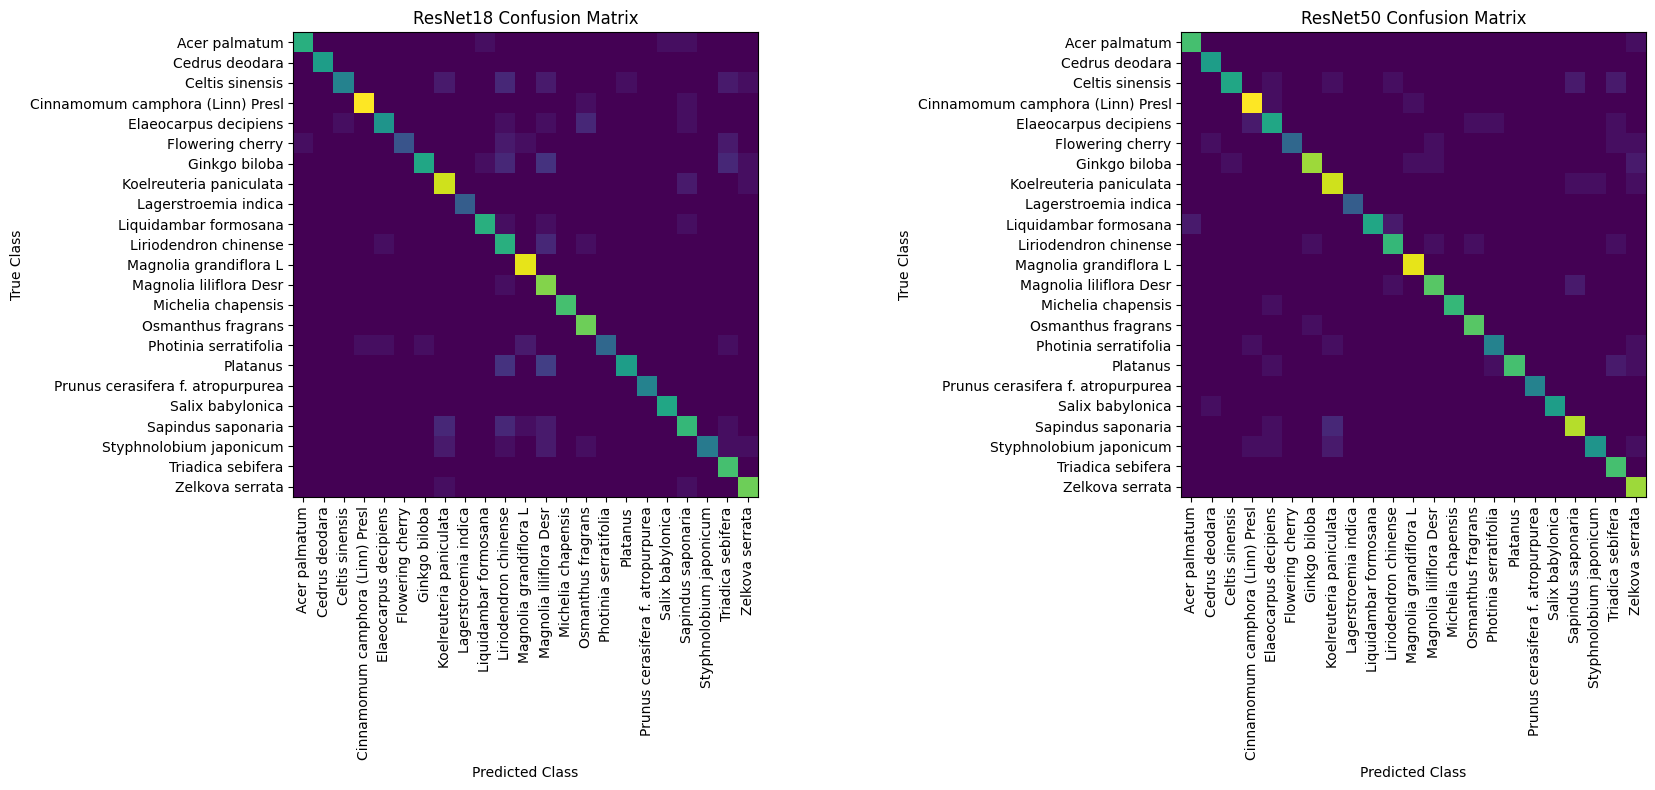

In [ ]:
# Display both confusion matrices side by side

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(cm18, interpolation="nearest")
axes[0].set_title("ResNet18 Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")
axes[0].set_xticks(np.arange(len(class_names)))
axes[0].set_yticks(np.arange(len(class_names)))
axes[0].set_xticklabels(class_names, rotation=90)
axes[0].set_yticklabels(class_names)

axes[1].imshow(cm50, interpolation="nearest")
axes[1].set_title("ResNet50 Confusion Matrix")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")
axes[1].set_xticks(np.arange(len(class_names)))
axes[1].set_yticks(np.arange(len(class_names)))
axes[1].set_xticklabels(class_names, rotation=90)
axes[1].set_yticklabels(class_names)

plt.tight_layout()
plt.show()

## 15.7 N-Best Classification Results

The n-best classification results evaluate whether the correct tree species appears within the top n predictions of each model.

For example, top-1 accuracy corresponds to normal classification accuracy. 
Top-3 accuracy measures how often the correct species is included among the three highest-probability predictions.

The purpose is to determine whether increasing n reveals a meaningful difference between ResNet18 and ResNet50.

In [ ]:
def top_k_accuracy(y_true, probabilities, k):
    top_k_predictions = np.argsort(probabilities, axis=1)[:, -k:]
    
    correct = 0
    
    for i in range(len(y_true)):
        if y_true[i] in top_k_predictions[i]:
            correct += 1
    
    return correct / len(y_true)


# Calculate top-k accuracy
max_k = 10

top_k_results18 = []
top_k_results50 = []

for k in range(1, max_k + 1):
    acc18 = top_k_accuracy(y_true18, y_prob18, k)
    acc50 = top_k_accuracy(y_true50, y_prob50, k)
    
    top_k_results18.append(acc18)
    top_k_results50.append(acc50)


# Print results
print("N-Best Classification Results")
print("-" * 45)

for k in range(1, max_k + 1):
    print(
        f"Top-{k}: "
        f"ResNet18 = {top_k_results18[k-1]:.4f} | "
        f"ResNet50 = {top_k_results50[k-1]:.4f}"
    )

N-Best Classification Results
---------------------------------------------
Top-1: ResNet18 = 0.8136 | ResNet50 = 0.8771
Top-2: ResNet18 = 0.8729 | ResNet50 = 0.9449
Top-3: ResNet18 = 0.9131 | ResNet50 = 0.9640
Top-4: ResNet18 = 0.9364 | ResNet50 = 0.9767
Top-5: ResNet18 = 0.9492 | ResNet50 = 0.9788
Top-6: ResNet18 = 0.9597 | ResNet50 = 0.9852
Top-7: ResNet18 = 0.9640 | ResNet50 = 0.9915
Top-8: ResNet18 = 0.9682 | ResNet50 = 0.9936
Top-9: ResNet18 = 0.9703 | ResNet50 = 0.9958
Top-10: ResNet18 = 0.9703 | ResNet50 = 0.9958


## 15.8 Visualization of N-Best Results

The top-k accuracy results are visualized to make the difference between the two models easier to observe.

The graph shows how classification accuracy changes as more possible predictions are considered.

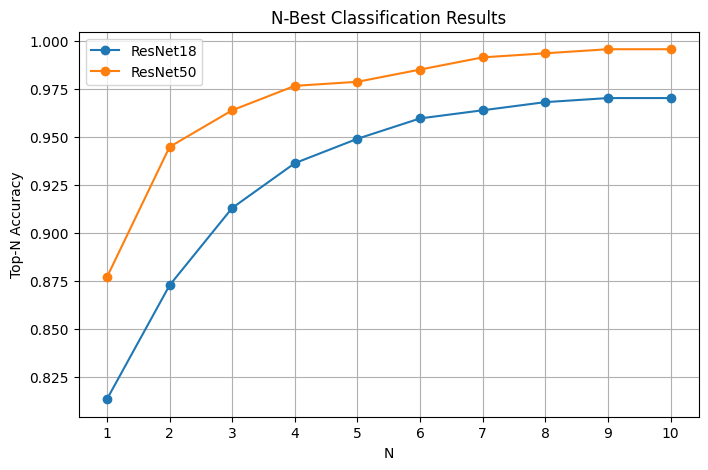

In [ ]:
k_values = range(1, max_k + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    top_k_results18,
    marker="o",
    label="ResNet18"
)

plt.plot(
    k_values,
    top_k_results50,
    marker="o",
    label="ResNet50"
)

plt.xlabel("N")
plt.ylabel("Top-N Accuracy")
plt.title("N-Best Classification Results")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)

plt.show()

### 15.9 Interpretation of N-Best Results

The models already have different performance at n = 1:
ResNet18 achieves 81.36%, while ResNet50 achieves 87.71%.

Among the tested values from n = 1 to n = 10, the largest
difference occurs at n = 2:

- ResNet18: 87.29%
- ResNet50: 94.49%
- Difference: approximately 7.20 percentage points

The difference generally becomes smaller as n increases.

Therefore, the models are already separated at n = 1.
There is no later value where separation first appears,
but n = 2 provides the largest observed separation within
the tested range.

## 15.10 Comparison of ResNet18 and ResNet50

The final test results of ResNet18 and ResNet50 are compared using accuracy, precision, recall, and F1-score.

The comparison is based on predictions from the same test dataset.

The results are also considered together with the confusion matrices and n-best classification results.

This provides a more complete evaluation than accuracy alone.

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "ResNet18": [
        accuracy18,
        precision18,
        recall18,
        f1_18
    ],
    "ResNet50": [
        accuracy50,
        precision50,
        recall50,
        f1_50
    ]
})

print(comparison)

      Metric  ResNet18  ResNet50
0   Accuracy  0.813559  0.877119
1  Precision  0.871070  0.897563
2     Recall  0.822230  0.880688
3   F1-score  0.825380  0.883119


## 15.11 Analysis of Misclassified Images

After evaluating the models, we inspect incorrectly classified test images.

The purpose is to identify repeated visual characteristics among the errors.

Possible factors include:

- Similar appearance between tree species
- Background objects
- Lighting conditions
- Different camera viewpoints
- Tree position in the image
- Occlusion
- Image quality
- The tree occupying only a small part of the image

The observations from this analysis will be used to decide whether an improvement to the preprocessing or data augmentation strategy is appropriate.

In [ ]:
# Find misclassified ResNet50 images

misclassified_indices50 = np.where(
    y_true50 != y_pred50
)[0]

print("Number of misclassified ResNet50 images:",
      len(misclassified_indices50))

Number of misclassified ResNet50 images: 58


## 15.12 Inspect ResNet50 Misclassifications

A sample of incorrectly classified images is displayed below.

The true class and predicted class are shown for each image.

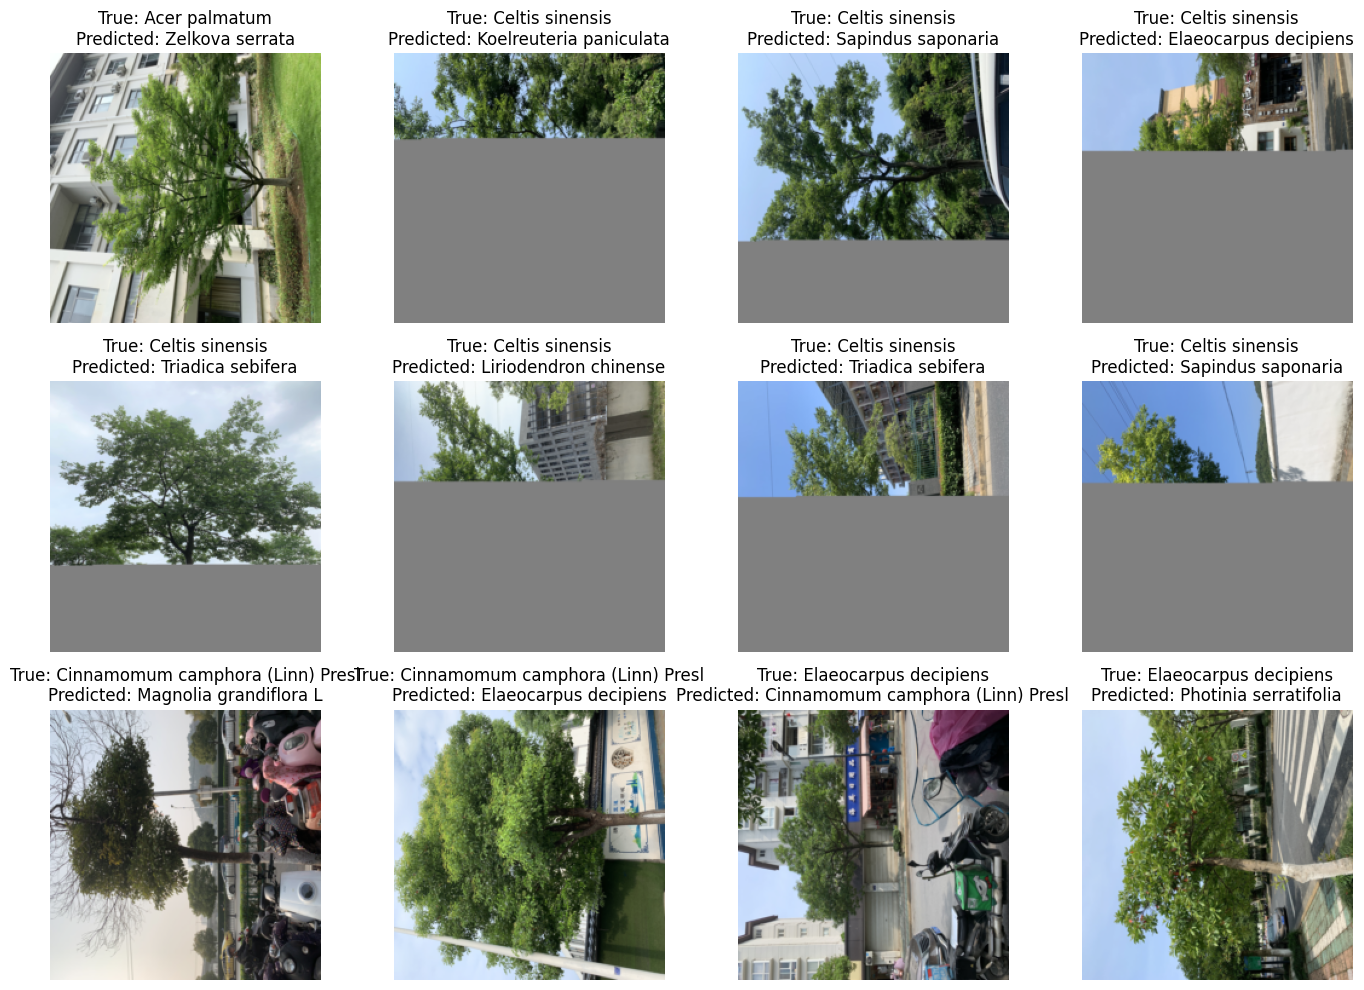

In [ ]:
# Display several misclassified images

num_images = min(12, len(misclassified_indices50))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i in range(num_images):
    
    idx = misclassified_indices50[i]
    
    image, true_label = test_dataset[idx]
    
    # Convert tensor image for displaying
    image_display = image.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    # Normalize values for display
    image_display = np.clip(
        (image_display * std) + mean, 0, 1)
    
    predicted_label = y_pred50[idx]
    
    axes[i].imshow(image_display)
    
    axes[i].set_title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}"
    )
    
    axes[i].axis("off")

for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# 16. Model Improvement

The initial evaluation showed that the models still make some classification errors between visually similar tree species.

The misclassified images were inspected to identify possible causes of these errors. Based on this analysis, an improvement strategy was selected and applied to the training process.

The improvement focuses on data preprocessing and augmentation. Data augmentation can expose the model to different variations of the same images, such as changes in orientation, scale, and lighting.

The improved model will then be trained using the modified training pipeline and evaluated using the same test dataset and evaluation metrics as the original models.

This allows the performance of the improved model to be compared with the original model.

## 16.1 Analysis of the Identified Errors

The misclassified images from the ResNet50 model were inspected to identify recurring visual characteristics.

Several possible sources of classification errors were observed:

- Similar visual appearance between some tree species
- Different backgrounds and surrounding objects
- Different lighting conditions
- Different camera viewpoints
- Different distances from the tree
- The tree occupying only part of the image

These variations can make it more difficult for the model to focus on the visual characteristics that are specific to each tree species.

Based on these observations, data augmentation was selected as the improvement strategy.

## 16.2 Apply Data Augmentation

The original model already used random cropping, horizontal
flipping, and rotation.

For the improvement experiment, we:
- Added brightness, contrast, and saturation changes.
- Increased rotation from 10 to 15 degrees.
- Removed random cropping.
- Resized training images directly to 224 × 224.

Colour changes were intended to help with lighting variation.
Removing cropping was intended to preserve tree features near
the image edges.

Several settings changed together, so we compare the complete
pipelines rather than claiming that one particular change
caused the improvement.

In [ ]:
from torchvision import transforms

improved_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
improved_train_data = datasets.ImageFolder(
    train_dir,
    transform=improved_train_transform
)

improved_val_data = datasets.ImageFolder(
    val_dir,
    transform=test_transform
)

improved_test_data = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

print("Improved datasets created successfully.")

Improved datasets created successfully.


In [ ]:
improved_train_loader = DataLoader(
    improved_train_data,
    batch_size=32,
    shuffle=True
)

improved_val_loader = DataLoader(
    improved_val_data,
    batch_size=32,
    shuffle=False
)

improved_test_loader = DataLoader(
    improved_test_data,
    batch_size=32,
    shuffle=False
)

print("Improved data loaders created successfully.")

Improved data loaders created successfully.


## 16.3 Train the Improved ResNet50 Model

ResNet50 was selected for the improvement experiment because it achieved higher performance than ResNet18 in the initial evaluation.

The same pretrained ResNet50 architecture is used, but the training dataset now includes additional data augmentation.

The validation and test datasets are not augmented because they should represent the original data distribution used for evaluation.

In [ ]:
model50_improved = models.resnet50(
    weights="IMAGENET1K_V2"
)

model50_improved.fc = nn.Linear(
    model50_improved.fc.in_features,
    num_classes
)

model50_improved = model50_improved.to(device)

criterion_improved = nn.CrossEntropyLoss()

optimizer_improved = optim.Adam(
    model50_improved.parameters(),
    lr=0.0001
)

print("Improved ResNet50 model created successfully.")

Improved ResNet50 model created successfully.


In [ ]:
epochs_improved = 5

train_losses_improved, val_losses_improved, \
train_accuracies_improved, val_accuracies_improved = train_model_best(
    model50_improved,
    improved_train_loader,
    improved_val_loader,
    criterion_improved,
    optimizer_improved,
    epochs_improved,
    "resnet50_improved_best.pth"
)

Best model saved to resnet50_improved_best.pth
Epoch [1/5] Train Loss: 2.3574 Train Accuracy: 37.35% Val Loss: 0.9936 Val Accuracy: 71.16%
Best model saved to resnet50_improved_best.pth
Epoch [2/5] Train Loss: 0.7642 Train Accuracy: 80.03% Val Loss: 0.4143 Val Accuracy: 88.38%
Best model saved to resnet50_improved_best.pth
Epoch [3/5] Train Loss: 0.3542 Train Accuracy: 89.97% Val Loss: 0.3121 Val Accuracy: 90.25%
Best model saved to resnet50_improved_best.pth
Epoch [4/5] Train Loss: 0.1998 Train Accuracy: 94.55% Val Loss: 0.2538 Val Accuracy: 92.12%
Best model saved to resnet50_improved_best.pth
Epoch [5/5] Train Loss: 0.1356 Train Accuracy: 96.49% Val Loss: 0.2287 Val Accuracy: 93.78%
Best validation accuracy: 93.7759336099585


In [ ]:
# Load the best improved ResNet50 model

model50_improved.load_state_dict(
    torch.load(
        "resnet50_improved_best.pth",
        map_location=device
    )
)

model50_improved = model50_improved.to(device)
model50_improved.eval()

print("Best improved ResNet50 model loaded successfully.")

Best improved ResNet50 model loaded successfully.


## 16.4 Evaluate the Improved ResNet50 Model

The improved ResNet50 model is evaluated using the same test dataset as the original model.

Accuracy, precision, recall, and F1-score are calculated using macro averaging so that each tree species contributes equally to the overall result.

The results are then compared with the original ResNet50 model.

In [ ]:
y_true_improved, y_pred_improved, y_prob_improved = get_predictions(
    model50_improved,
    improved_test_loader
)

In [ ]:
accuracy_improved = accuracy_score(
    y_true_improved,
    y_pred_improved
)

precision_improved = precision_score(
    y_true_improved,
    y_pred_improved,
    average="macro",
    zero_division=0
)

recall_improved = recall_score(
    y_true_improved,
    y_pred_improved,
    average="macro",
    zero_division=0
)

f1_improved = f1_score(
    y_true_improved,
    y_pred_improved,
    average="macro",
    zero_division=0
)

print("Improved ResNet50 Test Results")
print(f"Accuracy:  {accuracy_improved:.4f}")
print(f"Precision: {precision_improved:.4f}")
print(f"Recall:    {recall_improved:.4f}")
print(f"F1-score:  {f1_improved:.4f}")

Improved ResNet50 Test Results
Accuracy:  0.9004
Precision: 0.9088
Recall:    0.8964
F1-score:  0.8972


## 16.5 Comparison of Original and Improved ResNet50

The performance of the original ResNet50 model is compared with the improved ResNet50 model.

The comparison shows whether the selected data augmentation strategy improved the classification performance on the unseen test dataset.

In [ ]:
comparison_improved = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Original ResNet50": [
        accuracy50,
        precision50,
        recall50,
        f1_50
    ],
    "Improved ResNet50": [
        accuracy_improved,
        precision_improved,
        recall_improved,
        f1_improved
    ]
})

print(comparison_improved)

      Metric  Original ResNet50  Improved ResNet50
0   Accuracy           0.877119           0.900424
1  Precision           0.897563           0.908760
2     Recall           0.880688           0.896414
3   F1-score           0.883119           0.897231


In [ ]:
top_k_results_improved = [
    top_k_accuracy(y_true_improved, y_prob_improved, k)
    for k in range(1, max_k + 1)
]

top_n_comparison = pd.DataFrame({
    "n": range(1, max_k + 1),
    "ResNet18 (%)": np.array(top_k_results18) * 100,
    "Original ResNet50 (%)": np.array(top_k_results50) * 100,
    "Improved ResNet50 (%)": (
        np.array(top_k_results_improved) * 100
    )
})

print(top_n_comparison.round(2).to_string(index=False))

 n  ResNet18 (%)  Original ResNet50 (%)  Improved ResNet50 (%)
 1         81.36                  87.71                  90.04
 2         87.29                  94.49                  94.49
 3         91.31                  96.40                  96.40
 4         93.64                  97.67                  97.46
 5         94.92                  97.88                  98.09
 6         95.97                  98.52                  98.73
 7         96.40                  99.15                  98.73
 8         96.82                  99.36                  98.94
 9         97.03                  99.58                  98.94
10         97.03                  99.58                  99.36


### Discussion of the Improved Model’s N-Best Results

The modified ResNet50 improves top-1 accuracy from 87.71%
to 90.04%. However, it does not outperform the original
ResNet50 at every value of n.

Both models achieve the same accuracy at n = 2 and n = 3.
The modified model performs slightly better at n = 5 and
n = 6. The original model performs slightly better at
n = 4 and n = 7–10.

Therefore, the modification improves first-choice predictions,
but does not consistently improve top-n accuracy.

## 16.6 Confusion Matrix for the Improved ResNet50

The improved ResNet50 model is evaluated using a confusion matrix to examine
whether data augmentation changed the classification behaviour.

The confusion matrix shows the true tree species on the rows and the predicted
tree species on the columns.

The matrix can be compared with the original ResNet50 confusion matrix to
identify whether some of the previous classification errors were reduced after
the improvement.

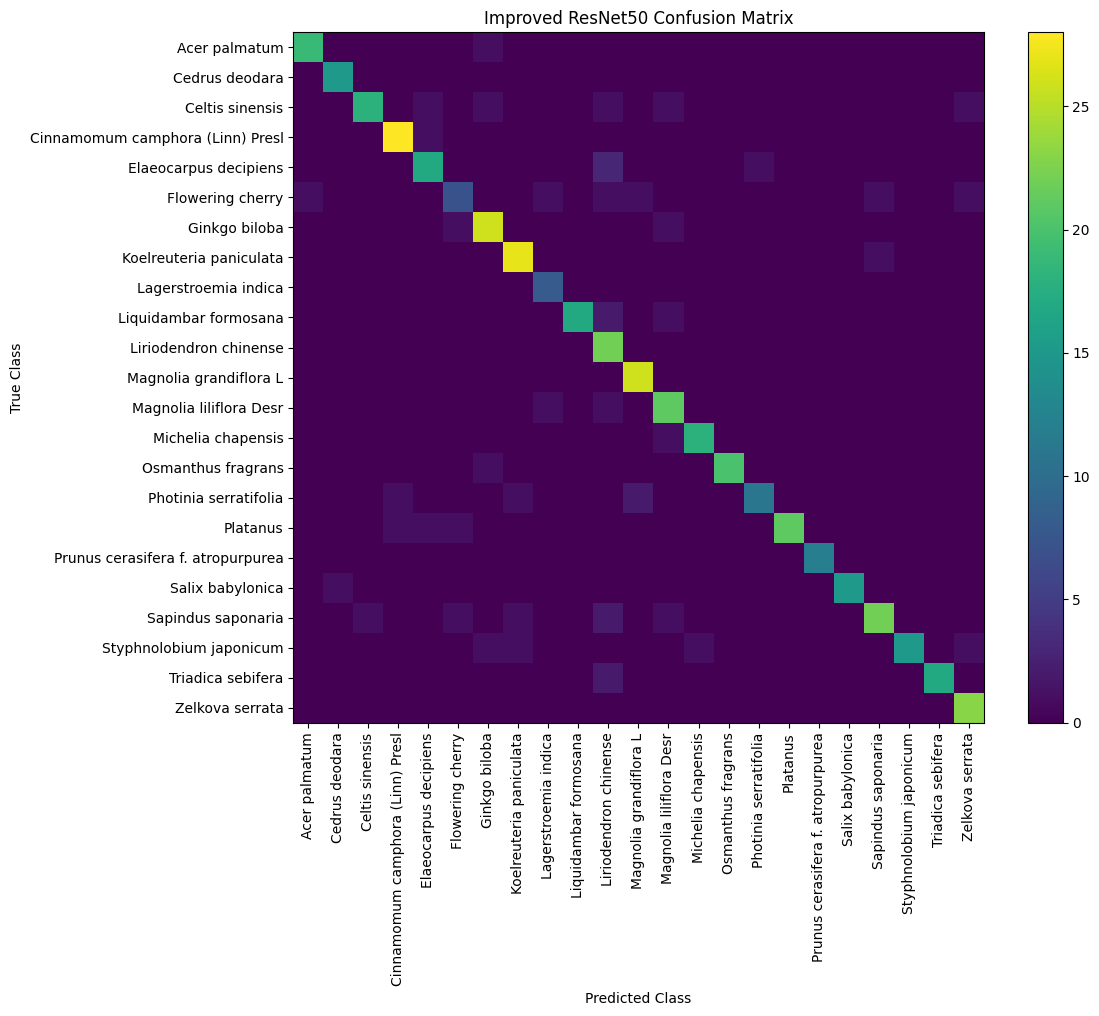

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Calculate confusion matrix for the improved ResNet50
cm_improved = confusion_matrix(
    y_true_improved,
    y_pred_improved
)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm_improved, interpolation="nearest", cmap="viridis")
plt.title("Improved ResNet50 Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

## 16.7 Comparison of Original and Improved Confusion Matrices

The confusion matrices of the original and improved ResNet50 models are
displayed side by side.

This comparison helps determine whether the data augmentation strategy
reduced confusion between particular tree species.

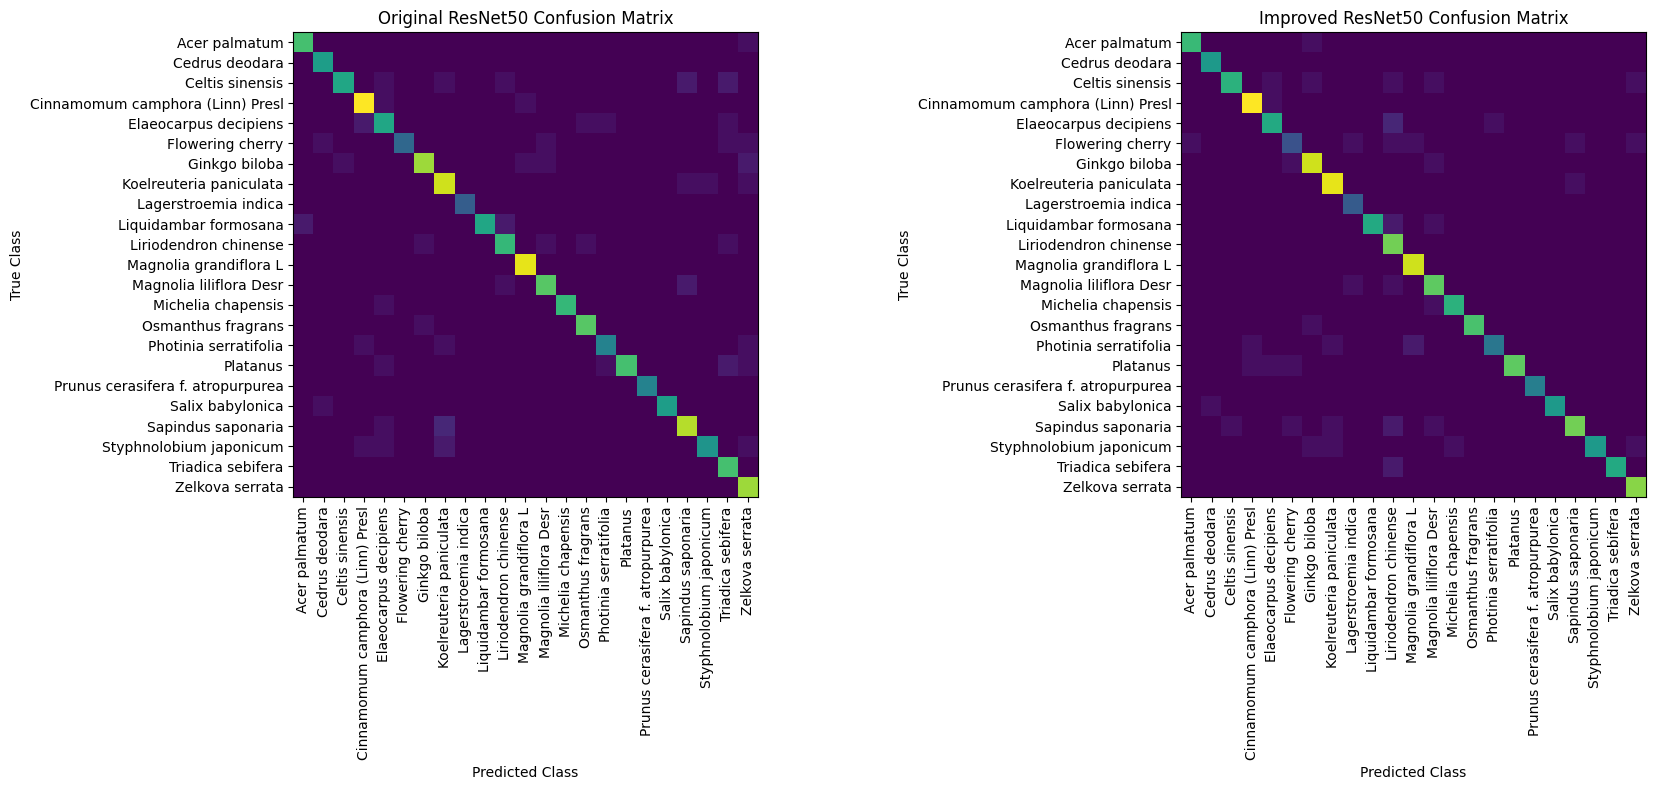

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Original ResNet50
axes[0].imshow(cm50, interpolation="nearest", cmap="viridis")
axes[0].set_title("Original ResNet50 Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

axes[0].set_xticks(np.arange(len(class_names)))
axes[0].set_xticklabels(class_names, rotation=90)

axes[0].set_yticks(np.arange(len(class_names)))
axes[0].set_yticklabels(class_names)

# Improved ResNet50
axes[1].imshow(cm_improved, interpolation="nearest", cmap="viridis")
axes[1].set_title("Improved ResNet50 Confusion Matrix")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")

axes[1].set_xticks(np.arange(len(class_names)))
axes[1].set_xticklabels(class_names, rotation=90)

axes[1].set_yticks(np.arange(len(class_names)))
axes[1].set_yticklabels(class_names)

plt.tight_layout()
plt.show()

In [ ]:
# Copy the original confusion matrix.
errors = cm50.copy()

# Ignore correct predictions on the diagonal.
np.fill_diagonal(errors, 0)

comparison_rows = []

# Examine the largest error counts first.
for index in np.argsort(errors.ravel())[::-1]:

    true_idx, predicted_idx = np.unravel_index(
        index, errors.shape
    )

    if errors[true_idx, predicted_idx] == 0:
        break

    original_count = int(
        cm50[true_idx, predicted_idx]
    )

    improved_count = int(
        cm_improved[true_idx, predicted_idx]
    )

    comparison_rows.append({
        "Actual species": class_names[true_idx],
        "Predicted as": class_names[predicted_idx],
        "Original mistakes": original_count,
        "Improved mistakes": improved_count,
        "Reduction": original_count - improved_count
    })

    if len(comparison_rows) == 3:
        break

confusion_comparison = pd.DataFrame(comparison_rows)

print(confusion_comparison.to_string(index=False))

         Actual species            Predicted as  Original mistakes  Improved mistakes  Reduction
     Sapindus saponaria Koelreuteria paniculata                  3                  1          2
  Liquidambar formosana   Liriodendron chinense                  2                  2          0
Styphnolobium japonicum Koelreuteria paniculata                  2                  1          1


### Discussion of Common Classification Errors

The table compares three of the original ResNet50 model’s most
common classification errors with the modified model.

- **Sapindus saponaria → Koelreuteria paniculata:** Mistakes
  decreased from 3 to 1, meaning the modified model made
  2 fewer errors for this confusion.

- **Liquidambar formosana → Liriodendron chinense:** Both
  models made 2 mistakes. The modified pipeline did not
  reduce this particular confusion.

- **Styphnolobium japonicum → Koelreuteria paniculata:**
  Mistakes decreased from 2 to 1, meaning the modified
  model made 1 fewer error for this confusion.

The modified model reduced two of these three confusion
types, while one remained unchanged. This shows that the
overall improvement was not uniform across species.

These counts show which errors changed, but do not establish
their visual causes. Further inspection of the corresponding
images could help determine whether tree appearance,
background, or lighting contributed to the remaining errors.

## 16.8 Analysis of the Model Improvement

The improved ResNet50 model was compared with the original ResNet50 model
using the same test dataset.

Data augmentation was applied to the training images to introduce additional
variation in image orientation, lighting, and appearance.

The improved model achieved higher test-set values for accuracy, precision, recall, and F1-score than the original ResNet50. This suggests that the selected data augmentation strategy improved performance on the test dataset for this experiment.

The confusion matrices are also examined to determine whether some of the
classification errors observed in the original model were reduced after
training with the augmented data.

The modified ResNet50 achieved 90.04% test accuracy compared
with 87.71% for the original ResNet50. This is an increase
of 2.33 percentage points, equivalent to 11 additional
correct predictions across 472 test images.

Macro F1 also increased, from 0.8831 to 0.8972.
The modified pipeline therefore performed better in this run.


## 16.9 Evaluation Limitation
We inspected test-set mistakes before choosing the modified
augmentation pipeline. Therefore, the test set influenced model
development, even though test images were not used for gradient
updates.

The improved result should therefore be interpreted as an
exploratory comparison rather than a fully independent final
evaluation.

In future experiments, we would use validation mistakes to
choose improvements and reserve an untouched test set for the
final assessment.


# 17. Overall Results and Conclusions

## 17.1 Overall Model Performance

The final test results of ResNet18, the original ResNet50, and the improved ResNet50 are compared using accuracy, precision, recall, and F1-score.

The original ResNet50 achieved substantially higher test performance than ResNet18. Therefore, ResNet50 was selected for the model improvement experiment.

After applying data augmentation to the training data, the improved ResNet50 achieved higher values for all four evaluation metrics on the test dataset.

This comparison shows that the selected augmentation strategy improved the classification performance of the ResNet50 model on the same test dataset.

## 17.2 Main Findings

Several observations were made during the experiments.

First, ResNet50 achieved higher classification performance than ResNet18 on the test dataset. This indicates that the larger ResNet architecture was able to learn more useful visual features for the tree species classification task.

Second, the confusion matrices showed that most predictions were concentrated along the diagonal, meaning that many images were correctly classified. However, some tree species were still confused with other visually similar species.

Third, the N-best classification results showed that allowing multiple possible predictions increased the probability that the correct tree species appeared among the model's top predictions.

Finally, the misclassified image analysis showed that differences in background, lighting, camera viewpoint, distance from the tree, and the amount of the tree visible in the image can make classification more difficult.

## 17.3 Effect of the Model Improvement

The improvement experiment used data augmentation on the training images.

The augmentation introduced additional variation in image orientation, lighting, and appearance. The validation and test datasets were kept without training augmentation so that the model could be evaluated on data representing the original image distribution.

The improved ResNet50 achieved higher accuracy, precision, recall, and F1-score than the original ResNet50 on the test dataset.

The confusion matrices were compared to examine changes in the classification
errors between the original and improved models.

Based on these results, the selected data augmentation strategy improved the performance of the ResNet50 model for this dataset.

## 17.4 Limitations and Possible Future Improvements

Although the improved model achieved good performance, some classification errors remained.

The dataset contains images captured under different conditions, including differences in lighting, background, viewpoint, distance, and visibility of the tree. These variations can make some species difficult to distinguish.

Possible future improvements could include:

- collecting more images for difficult tree species
- using a larger and more diverse training dataset
- applying additional data augmentation techniques
- investigating more advanced transfer learning strategies
- tuning the learning rate and other training parameters
- examining the most frequently confused species individually